<a href="https://colab.research.google.com/github/GOAT911/TP_ML/blob/main/TP1_ML_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 : Prétraitement du dataset Titanic

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Partie 1 : Découvrir les données
On charge le Titanic et on regarde à quoi il ressemble.

In [ ]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
df.info()   # types des colonnes

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [ ]:
df.isnull().sum()   # nombre de valeurs manquantes par colonne

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

- **Numériques** : survived, pclass, age, sibsp, parch, fare
- **Catégorielles** : sex, embarked, class, who, deck...
- **Valeurs manquantes** : `age` (177), `embarked` (2), `deck` (688)

## Partie 2 : Nettoyage

### Valeurs manquantes
- `deck` a plus de 40 % de manquants (688 sur 891) : on la **supprime**.
- `age` est numérique : on remplace par la **médiane**.
- `embarked` est catégorielle : on remplace par le **mode** (la valeur la plus fréquente).

In [ ]:
df = df.drop(columns=["deck"])
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

df[["age", "embarked"]].isnull().sum()   # doit afficher 0

age         0
embarked    0
dtype: int64

### Valeurs aberrantes
On les repère avec un boxplot : ce sont les points isolés loin de la boîte.

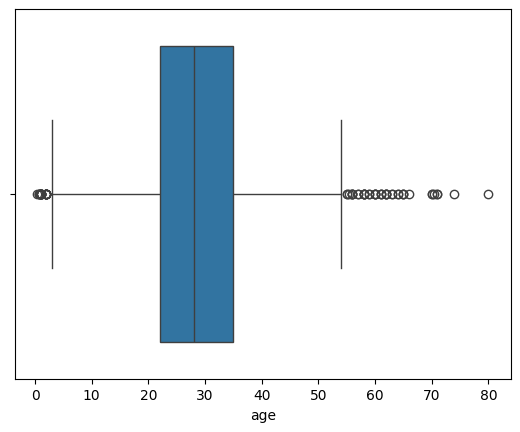

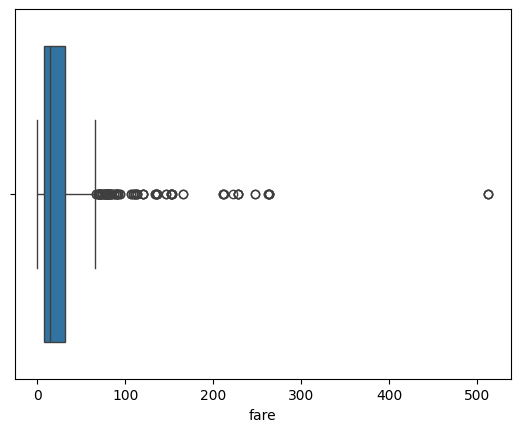

In [ ]:
sns.boxplot(x=df["age"])
plt.show()
sns.boxplot(x=df["fare"])
plt.show()

Pour les corriger, on calcule des limites avec l'IQR :
- limite basse = Q1 − 1.5 × IQR
- limite haute = Q3 + 1.5 × IQR

Ce qui est en dehors est remplacé par la **médiane**.

In [ ]:
for col in ["age", "fare"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    bas = Q1 - 1.5 * IQR
    haut = Q3 + 1.5 * IQR
    aberrantes = (df[col] < bas) | (df[col] > haut)
    print(col, ":", aberrantes.sum(), "valeurs aberrantes")
    df.loc[aberrantes, col] = df[col].median()

age : 66 valeurs aberrantes
fare : 116 valeurs aberrantes


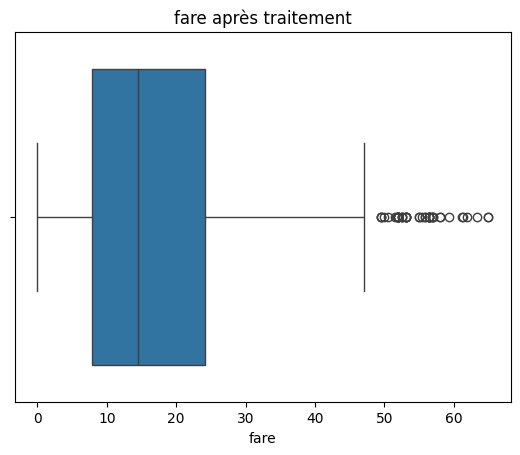

In [ ]:
sns.boxplot(x=df["fare"])
plt.title("fare après traitement")
plt.show()

## Partie 3 : Transformation

### Encodage
- `pclass` est **ordinale** (1 < 2 < 3) et déjà en chiffres : on ne change rien.
- `sex` et `embarked` sont **nominales** (pas d'ordre) : on utilise le **one-hot**, qui crée une colonne 0/1 par catégorie.

In [ ]:
df = pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True, dtype=int)
df[["sex_male", "embarked_Q", "embarked_S"]].head()

,sex_male,embarked_Q,embarked_S
0,1,0,1
1,0,0,0
2,0,0,1
3,0,0,1
4,1,0,1


### Normalisation et standardisation
- **Min-Max** : met les valeurs entre 0 et 1.
- **Z-score** : met la moyenne à 0 et l'écart-type à 1.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

colonnes = ["age", "fare"]

df_minmax = df.copy()
df_minmax[colonnes] = MinMaxScaler().fit_transform(df[colonnes])

df_zscore = df.copy()
df_zscore[colonnes] = StandardScaler().fit_transform(df[colonnes])

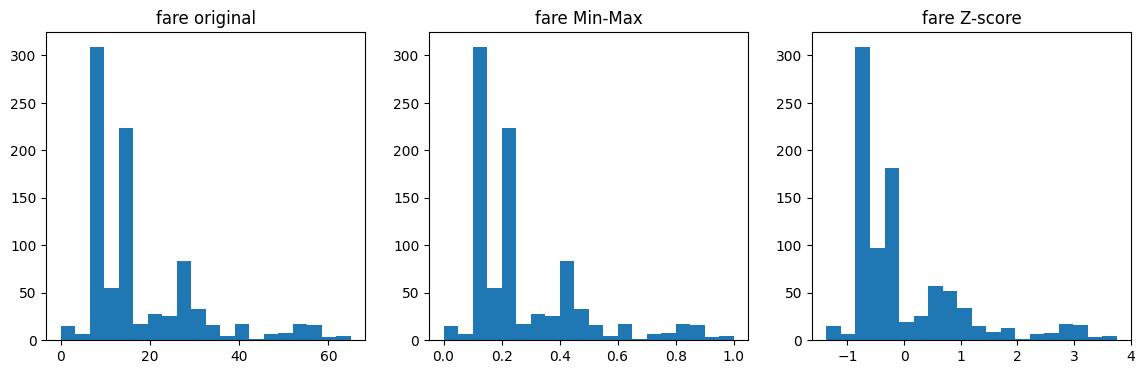

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df["fare"], bins=20);        axes[0].set_title("fare original")
axes[1].hist(df_minmax["fare"], bins=20); axes[1].set_title("fare Min-Max")
axes[2].hist(df_zscore["fare"], bins=20); axes[2].set_title("fare Z-score")
plt.show()

**Conclusion :** la forme de l'histogramme ne change pas, seule l'échelle de l'axe change.
Cela aide les modèles qui utilisent des distances (KNN, SVM, SMOTE...).

## Partie 4 : Données déséquilibrées

### Voir le déséquilibre

survived
0    549
1    342
Name: count, dtype: int64


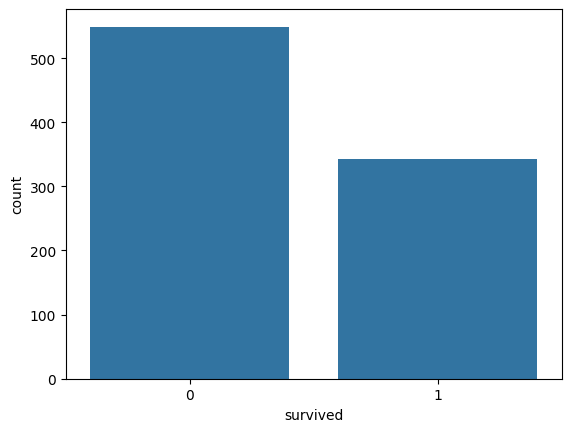

In [ ]:
print(df["survived"].value_counts())
sns.countplot(x="survived", data=df)
plt.show()

Il y a environ 62 % de morts et 38 % de survivants : la classe 0 est plus grande que la classe 1.

### Séparer train et test, puis standardiser
On sépare **avant** de rééquilibrer : le test doit rester intact, comme des données réelles.
Le scaler apprend (`fit`) sur le train seulement, puis s'applique (`transform`) au test.

In [ ]:
from sklearn.model_selection import train_test_split

X = df[["pclass", "age", "sibsp", "parch", "fare", "sex_male", "embarked_Q", "embarked_S"]]
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Sous-échantillonnage et SMOTE
- **Undersampling** : on supprime des exemples de la classe majoritaire.
- **SMOTE** : on crée de nouveaux exemples synthétiques pour la classe minoritaire.

In [ ]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

print("Avant         :", y_train.value_counts().to_dict())
print("Undersampling :", y_under.value_counts().to_dict())
print("SMOTE         :", y_smote.value_counts().to_dict())

Avant         : {0: 439, 1: 273}
Undersampling : {0: 273, 1: 273}
SMOTE         : {1: 439, 0: 439}


**Conclusion :** les deux classes ont maintenant le même nombre d'exemples (273/273 avec l'undersampling, 439/439 avec SMOTE).
Le rééquilibrage ne s'applique qu'au train : le test reste intact.